In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import LabelEncoder
import warnings

warnings.filterwarnings('ignore')

In [18]:
# --- 1. DATA PREPARATION ---
def prepare_inventory_data(df):
    df['Date'] = pd.to_datetime(df['Date'])
    df = df.sort_values(['Date', 'Store ID', 'Product ID'])

    # Encode categorical features
    le = LabelEncoder()
    for col in ['Category', 'Region', 'Weather Condition', 'Seasonality']:
        df[col] = le.fit_transform(df[col].astype(str))

    # Feature Engineering (Crucial for time-series)
    df['DayOfWeek'] = df['Date'].dt.dayofweek
    df['Month'] = df['Date'].dt.month
    df['Sales_Lag_1'] = df.groupby(['Store ID', 'Product ID'])['Units Sold'].shift(1)
    df['Sales_Lag_7'] = df.groupby(['Store ID', 'Product ID'])['Units Sold'].shift(7)
    df['Rolling_7'] = df.groupby(['Store ID', 'Product ID'])['Units Sold'].transform(lambda x: x.rolling(7).mean())

    return df.dropna()

In [19]:
# Load dataset (Replace path as needed)
df_raw = pd.read_csv('/content/retail_store_inventory.csv')
df = prepare_inventory_data(df_raw)

# Define columns
features = ['Category', 'Region', 'Price', 'Discount', 'Weather Condition',
            'DayOfWeek', 'Month', 'Sales_Lag_1', 'Sales_Lag_7', 'Rolling_7']
target = 'Units Sold'

# --- 2. THE TIMELINE SPLIT ---
# Train on 2022 + 2023 (Up to Aug 31)
train_cutoff = pd.Timestamp('2023-09-01')
train_initial = df[df['Date'] < train_cutoff]
simulation_period = df[df['Date'] >= train_cutoff].copy()

# Prepare weekly slots for simulation
simulation_period['Week_Year'] = simulation_period['Date'].dt.strftime('%Y-%U')
weeks = sorted(simulation_period['Week_Year'].unique())

In [20]:
# --- 3. STRATEGY A: STATIC (Control Group) ---
print("Training Static Model once (Final Training: Aug 31, 2023)...")
static_ensemble = VotingRegressor(
    estimators=[
        ('rf', RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)),
        ('xgb', XGBRegressor(n_jobs=-1, random_state=42)),
        ('lr', LinearRegression())
    ],
    weights=[0.4, 0.4, 0.2]
)
static_ensemble.fit(train_initial[features], train_initial[target])
static_preds_all = static_ensemble.predict(simulation_period[features])
static_mae_initial = mean_absolute_error(simulation_period[target], static_preds_all)
print(f"Static Model MAE (Baseline): {static_mae_initial:.2f}")

Training Static Model once (Final Training: Aug 31, 2023)...
Static Model MAE (Baseline): 80.33


In [21]:
# --- 4. STRATEGY B: ADAPTIVE (Experimental Group) ---
print(f"Starting Weekly Adaptive Retraining for {len(weeks)} weeks...")

adaptive_preds_all = []
weekly_performance = [] # This stores the results you asked for
current_history = train_initial.copy()

for i, week in enumerate(weeks):
    # Filter data for the current simulation week
    week_data = simulation_period[simulation_period['Week_Year'] == week]
    actuals = week_data[target].values

    # --- The "Serverless" Step: Train fresh model on updated history ---
    print(f"Week {i+1}/{len(weeks)} ({week}) | Retraining on {len(current_history)} rows...")

    adaptive_ensemble = VotingRegressor(
        estimators=[
            ('rf', RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)),
            ('xgb', XGBRegressor(n_jobs=-1, random_state=42)),
            ('lr', LinearRegression())
        ],
        weights=[0.4, 0.4, 0.2]
    )
    adaptive_ensemble.fit(current_history[features], current_history[target])

    # Predict & Store
    a_preds = adaptive_ensemble.predict(week_data[features])
    adaptive_preds_all.extend(a_preds)

    # --- EVALUATE THIS WEEK INDIVIDUALLY ---
    # Get the corresponding static predictions for this week to compare
    s_preds = static_preds_all[simulation_period['Week_Year'] == week]

    s_mae = mean_absolute_error(actuals, s_preds)
    a_mae = mean_absolute_error(actuals, a_preds)

    weekly_performance.append({
        'Week': week,
        'Static_MAE': s_mae,
        'Adaptive_MAE': a_mae,
        'Improvement_Delta': s_mae - a_mae
    })

    # --- Update "NoSQL" History for next week's training ---
    current_history = pd.concat([current_history, week_data])

Starting Weekly Adaptive Retraining for 20 weeks...
Week 1/20 (2023-35) | Retraining on 60100 rows...
Week 2/20 (2023-36) | Retraining on 60300 rows...
Week 3/20 (2023-37) | Retraining on 61000 rows...
Week 4/20 (2023-38) | Retraining on 61700 rows...
Week 5/20 (2023-39) | Retraining on 62400 rows...
Week 6/20 (2023-40) | Retraining on 63100 rows...
Week 7/20 (2023-41) | Retraining on 63800 rows...
Week 8/20 (2023-42) | Retraining on 64500 rows...
Week 9/20 (2023-43) | Retraining on 65200 rows...
Week 10/20 (2023-44) | Retraining on 65900 rows...
Week 11/20 (2023-45) | Retraining on 66600 rows...
Week 12/20 (2023-46) | Retraining on 67300 rows...
Week 13/20 (2023-47) | Retraining on 68000 rows...
Week 14/20 (2023-48) | Retraining on 68700 rows...
Week 15/20 (2023-49) | Retraining on 69400 rows...
Week 16/20 (2023-50) | Retraining on 70100 rows...
Week 17/20 (2023-51) | Retraining on 70800 rows...
Week 18/20 (2023-52) | Retraining on 71500 rows...
Week 19/20 (2023-53) | Retraining on 72


--- SUMMARY OF RESULTS ---
Average Static MAE: 79.97
Average Adaptive MAE: 79.80
Overall Improvement: 0.22%


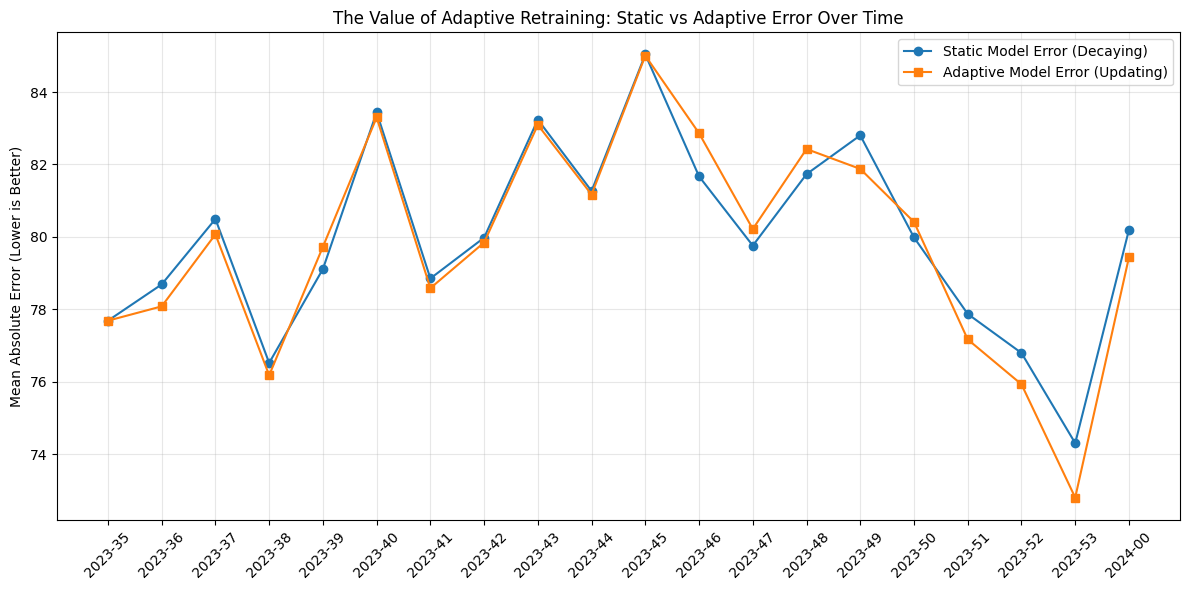

In [24]:
# --- 5. FINAL RESULTS ---
performance_df = pd.DataFrame(weekly_performance)

print("\n--- SUMMARY OF RESULTS ---")
print(f"Average Static MAE: {performance_df['Static_MAE'].mean():.2f}")
print(f"Average Adaptive MAE: {performance_df['Adaptive_MAE'].mean():.2f}")
print(f"Overall Improvement: {((performance_df['Static_MAE'].mean() - performance_df['Adaptive_MAE'].mean()) / performance_df['Static_MAE'].mean())*100:.2f}%")

# Plotting the Drift
plt.figure(figsize=(12, 6))
plt.plot(performance_df['Week'], performance_df['Static_MAE'], label='Static Model Error (Decaying)', marker='o')
plt.plot(performance_df['Week'], performance_df['Adaptive_MAE'], label='Adaptive Model Error (Updating)', marker='s')
plt.xticks(rotation=45)
plt.ylabel('Mean Absolute Error (Lower is Better)')
plt.title('The Value of Adaptive Retraining: Static vs Adaptive Error Over Time')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# SAVE THE PLOT
# Use a high DPI (dots per inch) for professional quality in your paper
plt.savefig('inventory_forecast_drift.png', dpi=300, bbox_inches='tight')
plt.savefig('inventory_forecast_drift.pdf', bbox_inches='tight')

plt.show()


--- FINAL WEEK COMPARISON (2024-00) ---
Static MAE: 80.20
Adaptive MAE: 79.44
Final Week Improvement: 0.76 units


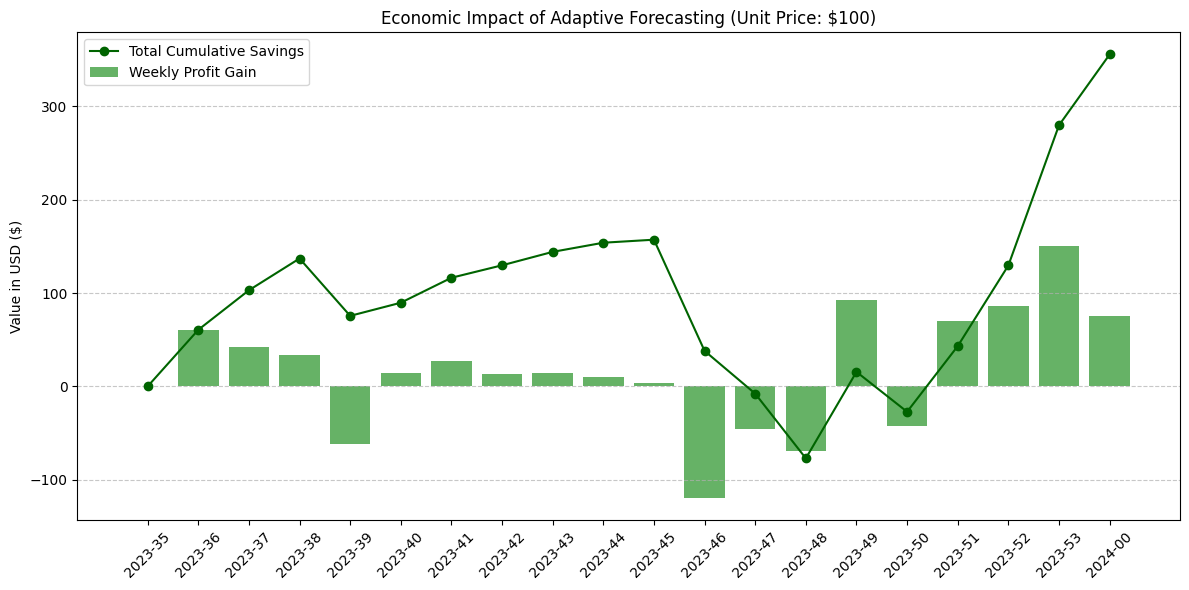


Total Cumulative Profit Saved: $355.51


In [25]:
# --- 6. PROFIT & FINAL COMPARISON ---
UNIT_PRICE = 100
# We assume every unit of "Error" (MAE) represents a lost profit opportunity
# (either cost of holding or cost of lost sale)
performance_df['Static_Loss'] = performance_df['Static_MAE'] * UNIT_PRICE
performance_df['Adaptive_Loss'] = performance_df['Adaptive_MAE'] * UNIT_PRICE

# Savings is the difference between the two losses
performance_df['Weekly_Savings'] = performance_df['Static_Loss'] - performance_df['Adaptive_Loss']
performance_df['Cumulative_Savings'] = performance_df['Weekly_Savings'].cumsum()

# 1. Print the "Final Week" Comparison
last_week = performance_df.iloc[-1]
print(f"\n--- FINAL WEEK COMPARISON ({last_week['Week']}) ---")
print(f"Static MAE: {last_week['Static_MAE']:.2f}")
print(f"Adaptive MAE: {last_week['Adaptive_MAE']:.2f}")
print(f"Final Week Improvement: {last_week['Improvement_Delta']:.2f} units")

# 2. Plotting the Profit Impact
plt.figure(figsize=(12, 6))
plt.bar(performance_df['Week'], performance_df['Weekly_Savings'], color='green', alpha=0.6, label='Weekly Profit Gain')
plt.plot(performance_df['Week'], performance_df['Cumulative_Savings'], color='darkgreen', marker='o', label='Total Cumulative Savings')

plt.xticks(rotation=45)
plt.ylabel('Value in USD ($)')
plt.title(f'Economic Impact of Adaptive Forecasting (Unit Price: ${UNIT_PRICE})')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# SAVE THE PLOT
# Use a high DPI (dots per inch) for professional quality in your paper
plt.savefig('Profit_forecast_drift.png', dpi=300, bbox_inches='tight')
plt.savefig('Profit_forecast_drift.pdf', bbox_inches='tight')
plt.show()

print(f"\nTotal Cumulative Profit Saved: ${performance_df['Weekly_Savings'].sum():.2f}")